In [2]:
import warnings
import pandas as pd

# Suppress DeprecationWarnings and other noisy warnings globally
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore')

# Reload preprocessed combined dataset to prevent NameError in subsequent cells
try:
    df = pd.read_csv('preprocessed_combined.csv')
    df['date'] = pd.to_datetime(df['date'])
    print("Successfully loaded 'df' from 'preprocessed_combined.csv' with shape:", df.shape)
except FileNotFoundError:
    print("Could not find 'preprocessed_combined.csv'. Please make sure the preprocessing steps are run first.")

Could not find 'preprocessed_combined.csv'. Please make sure the preprocessing steps are run first.


In [3]:
!pip install kagglehub --quiet

import kagglehub

#Dataset 1: Global Fuel Price Trends
fuel_path = kagglehub.dataset_download("minahilfatima12328/global-fuel-price-trends-19702026")
print("Fuel dataset path:", fuel_path)

#Dataset 2: Gold Price Dynamics
gold_path = kagglehub.dataset_download("novandraanugrah/xauusd-gold-price-historical-data-2004-2024")
print("Gold dataset path:", gold_path)

#Dataset 3: Nifty 100 Algo Trading Data
nifty_path = kagglehub.dataset_download("debashis74017/algo-trading-data-nifty-100-data-with-indicators")
print("Nifty dataset path:", nifty_path)

Using Colab cache for faster access to the 'global-fuel-price-trends-19702026' dataset.
Fuel dataset path: /kaggle/input/global-fuel-price-trends-19702026
Using Colab cache for faster access to the 'xauusd-gold-price-historical-data-2004-2024' dataset.
Gold dataset path: /kaggle/input/xauusd-gold-price-historical-data-2004-2024
Using Colab cache for faster access to the 'algo-trading-data-nifty-100-data-with-indicators' dataset.
Nifty dataset path: /kaggle/input/algo-trading-data-nifty-100-data-with-indicators


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# list CSV files in a path
import os
def list_csvs(path):
    return [f for f in os.listdir(path) if f.endswith('.csv')]

print("=" * 60)
print("FILES IN EACH DATASET")
print("=" * 60)
print("Fuel:", list_csvs(fuel_path))
print("Gold:", list_csvs(gold_path))
print("Nifty:", list_csvs(nifty_path))

# Load (adjust filenames based on output above)

fuel_files = list_csvs(fuel_path)
gold_files = list_csvs(gold_path)
nifty_files = list_csvs(nifty_path)

fuel_df  = pd.read_csv(os.path.join(fuel_path, fuel_files[0]))
# Use sep=';' because XAU_1h_data.csv is semicolon-separated
gold_df  = pd.read_csv(os.path.join(gold_path, gold_files[0]), sep=';')
nifty_df = pd.read_csv(os.path.join(nifty_path, nifty_files[0]))

# Standardize column names to lowercase
fuel_df.columns = fuel_df.columns.str.lower()
gold_df.columns = gold_df.columns.str.lower()
nifty_df.columns = nifty_df.columns.str.lower()

print("\n" + "=" * 60)
print("INITIAL SHAPES")
print("=" * 60)
print(f"Fuel   : {fuel_df.shape}")
print(f"Gold   : {gold_df.shape}")
print(f"Nifty  : {nifty_df.shape}")

print("\n--- Fuel Columns ---")
print(fuel_df.dtypes)
print("\n--- Gold Columns ---")
print(gold_df.dtypes)
print("\n--- Nifty Columns ---")
print(nifty_df.dtypes)

print("\n--- Fuel Head ---")
display(fuel_df.head(3))
print("\n--- Gold Head ---")
display(gold_df.head(3))
print("\n--- Nifty Head ---")
display(nifty_df.head(3))

FILES IN EACH DATASET
Fuel: ['fuel_prices_1970_2026.csv']
Gold: ['XAU_1m_data.csv', 'XAU_1w_data.csv', 'XAU_5m_data.csv', 'XAU_15m_data.csv', 'XAU_30m_data.csv', 'XAU_4h_data.csv', 'XAU_1d_data.csv', 'XAU_1Month_data.csv', 'XAU_1h_data.csv']
Nifty: ['KIRLOSENG_minute.csv', 'WELCORP_minute.csv', 'RHIM_minute.csv', 'RADICO_minute.csv', 'STARHEALTH_minute.csv', 'DEEPAKFERT_minute.csv', 'EICHERMOT_minute.csv', 'TATACAP_minute.csv', 'SWANCORP_minute.csv', 'APLLTD_minute.csv', 'ANURAS_minute.csv', 'GVTD_minute_new.csv', 'GRAVITA_minute.csv', 'SYNGENE_minute.csv', 'PFC_minute.csv', 'BANKINDIA_minute.csv', 'TORNTPHARM_minute.csv', 'HDFCBANK_minute.csv', 'FINCABLES_minute.csv', 'VENTIVE_minute.csv', 'AGARWALEYE_minute.csv', 'BPCL_minute.csv', 'VBL_minute.csv', 'SARDAEN_minute.csv', 'CENTRALBK_minute.csv', 'INDUSTOWER_minute.csv', 'SPLPETRO_minute.csv', 'ADANIENT_minute.csv', 'BSOFT_minute.csv', 'SUNTV_minute.csv', 'FINPIPE_minute.csv', 'JAINREC_minute.csv', 'SIEMENS_minute.csv', 'GLAXO_minute.c

,date,crude_oil_price
0,1970-01-01,1.21
1,1970-02-01,1.21
2,1970-03-01,1.21



--- Gold Head ---


,date,open,high,low,close,volume
0,2004.06.11 07:18,384.0,384.1,384.0,384.0,3
1,2004.06.11 07:23,384.1,384.1,384.0,384.0,2
2,2004.06.11 07:24,383.8,383.8,383.8,383.8,1



--- Nifty Head ---


,date,open,high,low,close,volume
0,2015-02-02 09:15:00,261.95,269.8,261.95,269.8,2
1,2015-02-02 09:16:00,269.80,269.8,269.80,269.8,0
2,2015-02-02 09:17:00,269.80,269.8,269.80,269.8,0


In [5]:
print("=" * 60)
print("NULL & DUPLICATE AUDIT")
print("=" * 60)
for name, d in [("Fuel", fuel_df), ("Gold", gold_df)]:
    print(f"{name}: total nulls = {d.isnull().sum().sum()}, duplicate rows = {d.duplicated().sum()}")

# Drop duplicates
fuel_df = fuel_df.drop_duplicates()
gold_df = gold_df.drop_duplicates()

# Fix datetime columns
fuel_df['date'] = pd.to_datetime(fuel_df['date'], errors='coerce')
gold_df['date'] = pd.to_datetime(gold_df['date'], errors='coerce')
print("Unreadable dates -> Fuel:", fuel_df['date'].isnull().sum(), "| Gold:", gold_df['date'].isnull().sum())

# Remove rows with bad dates, forward-fill remaining missing numbers
fuel_df = fuel_df.dropna(subset=['date']).sort_values('date').ffill()
gold_df = gold_df.dropna(subset=['date']).sort_values('date').ffill()

print("\nNulls after cleaning -> Fuel:", fuel_df.isnull().sum().sum(), "| Gold:", gold_df.isnull().sum().sum())
print("Fuel date range:", fuel_df['date'].min().date(), "->", fuel_df['date'].max().date())
print("Gold date range:", gold_df['date'].min().date(), "->", gold_df['date'].max().date())

NULL & DUPLICATE AUDIT
Fuel: total nulls = 0, duplicate rows = 0
Gold: total nulls = 0, duplicate rows = 0
Unreadable dates -> Fuel: 0 | Gold: 0

Nulls after cleaning -> Fuel: 0 | Gold: 0
Fuel date range: 1970-01-01 -> 2026-03-01
Gold date range: 2004-06-11 -> 2026-01-30


In [6]:
import os

# Verify that nifty_path is correctly defined and exists
print("Checking nifty_path:", nifty_path)
assert os.path.exists(nifty_path), f"Error: nifty_path '{nifty_path}' does not exist!"

nifty_files_check = [f for f in os.listdir(nifty_path) if f.endswith('.csv')]
print(f"Success: nifty_path is valid and contains {len(nifty_files_check)} CSV files.")

Checking nifty_path: /kaggle/input/algo-trading-data-nifty-100-data-with-indicators
Success: nifty_path is valid and contains 536 CSV files.


In [9]:
# ---------- Step A: build Nifty 100 index from a subset of stock files ----------
import numpy as np
import pandas as pd
import os

def monthly_close(file_path):
    # Optimized reading: read only the required columns and parsing dates faster
    d = pd.read_csv(file_path, usecols=['date', 'close'])
    d['month'] = d['date'].str[:7]                  # '2015-02-02 09:15:00' -> '2015-02'
    return d.groupby('month')['close'].last()       # last price of each month

stock_prices = {}
# To make this cell run extremely fast, we sample 15 representative stocks instead of processing all 536
import random
np.random.seed(42)
sampled_files = np.random.choice(nifty_files, size=min(15, len(nifty_files)), replace=False)

print(f"Processing a subset of {len(sampled_files)} stocks to build index quickly...")
for f in sampled_files:
    stock_name = f.replace('_minute.csv', '')
    full_path = os.path.join(nifty_path, f)
    try:
        stock_prices[stock_name] = monthly_close(full_path)
    except Exception as e:
        continue

stock_prices = pd.DataFrame(stock_prices)           # rows = months, columns = stocks
stock_prices.index = pd.to_datetime(stock_prices.index)
print("Stock price table (months x stocks):", stock_prices.shape)

stock_ret = stock_prices.pct_change() * 100         # monthly % return of every stock
stock_ret = stock_ret.where(stock_ret.abs() < 40)   # ignore split / bad-data jumps
nifty_ret = stock_ret.mean(axis=1)                  # average return of all stocks
nifty_index = 100 * (1 + nifty_ret.fillna(0) / 100).cumprod()   # index, base = 100
nifty_index.name = 'nifty_close'

# ---------- Step B: monthly fuel and gold ----------
fuel_monthly = fuel_df.set_index('date')['crude_oil_price'].resample('MS').last()
gold_monthly = gold_df.set_index('date')['close'].resample('MS').last()

# ---------- Step C: merge on common months ----------
merged = pd.concat([fuel_monthly, gold_monthly, nifty_index], axis=1, join='inner')
merged.columns = ['fuel_price', 'gold_price', 'nifty_close']
merged = merged.dropna().reset_index()
merged = merged.rename(columns={merged.columns[0]: 'date'})

print(f"\nMerged dataset shape: {merged.shape}")
print(f"Date range: {merged['date'].min().date()} -> {merged['date'].max().date()}")
display(merged.head(5))

Processing a subset of 15 stocks to build index quickly...
Stock price table (months x stocks): (135, 15)

Merged dataset shape: (132, 4)
Date range: 2015-02-01 -> 2026-01-01


,date,fuel_price,gold_price,nifty_close
0,2015-02-01,54.790000,1212.78,100.000000
1,2015-03-01,52.826667,1183.57,96.567717
2,2015-04-01,57.543333,1183.97,95.760866
3,2015-05-01,62.506667,1190.42,102.309574
4,2015-06-01,61.306667,1171.83,100.259839


In [10]:
df = merged.copy()

# Percentage monthly returns
df['fuel_pct']  = df['fuel_price'].pct_change() * 100
df['gold_pct']  = df['gold_price'].pct_change() * 100
df['nifty_pct'] = df['nifty_close'].pct_change() * 100

# Log returns
df['fuel_log_ret']  = np.log(df['fuel_price']  / df['fuel_price'].shift(1))
df['gold_log_ret']  = np.log(df['gold_price']  / df['gold_price'].shift(1))
df['nifty_log_ret'] = np.log(df['nifty_close'] / df['nifty_close'].shift(1))

# Gold-Fuel ratio (barrels of oil per ounce of gold)
df['gold_fuel_ratio'] = df['gold_price'] / df['fuel_price']

# Lagged features (what happened 1 and 2 months ago)
df['fuel_pct_lag1']  = df['fuel_pct'].shift(1)
df['fuel_pct_lag2']  = df['fuel_pct'].shift(2)
df['gold_pct_lag1']  = df['gold_pct'].shift(1)
df['nifty_pct_lag1'] = df['nifty_pct'].shift(1)

# Rolling averages
df['fuel_ma3']  = df['fuel_price'].rolling(3).mean()
df['gold_ma3']  = df['gold_price'].rolling(3).mean()
df['nifty_ma3'] = df['nifty_close'].rolling(3).mean()

# Discretization: fuel moved more than 5% -> rose/fell, else stable
df['fuel_cat']  = pd.cut(df['fuel_pct'], bins=[-np.inf, -5, 5, np.inf], labels=['fell', 'stable', 'rose'])
df['nifty_dir'] = (df['nifty_pct'] > 0).astype(int)      # 1 = up, 0 = down

# TARGETS = NEXT month
df['nifty_next_pct'] = df['nifty_pct'].shift(-1)
df['gold_next_pct']  = df['gold_pct'].shift(-1)
df['nifty_next_dir'] = (df['nifty_next_pct'] > 0).astype(int)

# Economic eras
df['year'] = df['date'].dt.year
def label_era(yr):
    if yr <= 2016:   return '1 Oil-Crash 2015-16'
    elif yr <= 2019: return '2 Stable 2017-19'
    elif yr == 2020: return '3 COVID 2020'
    else:            return '4 Post-COVID 2021+'
df['era'] = df['year'].apply(label_era)

# Drop rows with NaN created by returns / lags / next-month targets
df = df.dropna().reset_index(drop=True)

df.to_csv('preprocessed_combined.csv', index=False)
print(f"Feature engineering complete. Dataset shape: {df.shape}")
display(df.head(3))

Feature engineering complete. Dataset shape: (128, 25)


,date,fuel_price,gold_price,nifty_close,fuel_pct,gold_pct,nifty_pct,fuel_log_ret,gold_log_ret,nifty_log_ret,...,fuel_ma3,gold_ma3,nifty_ma3,fuel_cat,nifty_dir,nifty_next_pct,gold_next_pct,nifty_next_dir,year,era
0,2015-05-01,62.506667,1190.42,102.309574,8.625384,0.544777,6.838605,0.082735,0.005433,0.066149,...,57.625556,1185.986667,98.212719,rose,1,-2.003463,-1.561634,0,2015,1 Oil-Crash 2015-16
1,2015-06-01,61.306667,1171.83,100.259839,-1.919795,-1.561634,-2.003463,-0.019385,-0.015740,-0.020238,...,60.452222,1182.073333,99.443426,stable,0,9.531276,-6.515450,1,2015,1 Oil-Crash 2015-16
2,2015-07-01,54.340000,1095.48,109.815880,-11.363636,-6.515450,9.531276,-0.120628,-0.067374,0.091040,...,59.384444,1152.576667,104.128431,fell,1,-8.949016,3.581079,0,2015,1 Oil-Crash 2015-16


In [11]:
cols = ['fuel_price', 'gold_price', 'nifty_close']
stats_df = df[cols].agg(['mean', 'median', 'std', 'var', 'min', 'max'])
stats_df.loc['range']          = stats_df.loc['max'] - stats_df.loc['min']
stats_df.loc['mode']           = df[cols].round(0).mode().iloc[0]
stats_df.loc['mean_deviation'] = df[cols].apply(lambda x: (x - x.mean()).abs().mean())

print("--- Overall Stats (price levels) ---")
display(stats_df.round(2))

print("\n--- Monthly return (%) statistics ---")
display(df[['fuel_pct', 'gold_pct', 'nifty_pct']].agg(['mean', 'std', 'min', 'max']).round(2))

print("\n--- Standard Deviation of monthly return by Year ---")
display(df.groupby('year')[['fuel_pct', 'gold_pct', 'nifty_pct']].std().round(2))

print("\n--- Mean price by Economic Era ---")
display(df.groupby('era')[cols].mean().round(2))

print("\nInsight: higher standard deviation = more volatile year / era.")

--- Overall Stats (price levels) ---


,fuel_price,gold_price,nifty_close
mean,64.61,1792.49,258.55
median,63.48,1720.70,177.42
std,17.93,675.22,149.34
var,321.46,455916.36,22303.01
min,21.04,1060.81,91.98
max,116.80,4318.36,579.14
range,95.76,3257.55,487.16
mode,60.00,1269.00,156.00
mean_deviation,14.12,479.56,126.27



--- Monthly return (%) statistics ---


,fuel_pct,gold_pct,nifty_pct
mean,0.53,1.10,1.52
std,10.11,4.04,5.31
min,-39.63,-8.16,-21.29
max,44.37,10.92,16.32



--- Standard Deviation of monthly return by Year ---


,fuel_pct,gold_pct,nifty_pct
year,,,
2015,8.86,3.77,5.59
2016,11.10,5.79,6.30
2017,5.00,2.46,2.26
2018,8.31,2.43,4.59
2019,5.98,3.76,4.61
2020,23.71,4.74,9.56
2021,7.10,4.25,4.26
2022,10.73,3.87,5.47
2023,6.89,4.33,4.53



--- Mean price by Economic Era ---


,fuel_price,gold_price,nifty_close
era,,,
1 Oil-Crash 2015-16,45.53,1198.48,107.56
2 Stable 2017-19,60.85,1311.55,152.78
3 COVID 2020,41.26,1777.10,162.74
4 Post-COVID 2021+,77.89,2282.13,391.51



Insight: higher standard deviation = more volatile year / era.


In [12]:
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, pearsonr

# 1. Pearson Correlation
print("--- 1. Pearson Correlation on PRICES (can be misleading) ---")
display(df[['fuel_price', 'gold_price', 'nifty_close']].corr().round(3))

print("--- Pearson Correlation on monthly RETURNS (correct way) ---")
display(df[['fuel_pct', 'gold_pct', 'nifty_pct']].corr().round(3))

r_fg, p_fg = pearsonr(df['fuel_pct'], df['gold_pct'])
r_fn, p_fn = pearsonr(df['fuel_pct'], df['nifty_pct'])
print(f"Fuel vs Gold  (returns) -> r = {r_fg:.3f}, p = {p_fg:.4f}")
print(f"Fuel vs Nifty (returns) -> r = {r_fn:.3f}, p = {p_fn:.4f}")

# 2. t-test: Nifty returns before 2020 vs from 2020 onwards
print("\n--- 2. t-test: Nifty monthly return, Pre-2020 vs 2020 onwards ---")
pre  = df[df['year'] < 2020]['nifty_pct']
post = df[df['year'] >= 2020]['nifty_pct']
t_stat, p_val = ttest_ind(pre, post, equal_var=False)
print(f"Pre-2020 mean return : {pre.mean():.2f}%")
print(f"2020+ mean return    : {post.mean():.2f}%")
print(f"t-statistic = {t_stat:.4f}, p-value = {p_val:.4f}")
if p_val < 0.05:
    print("Significant difference (p < 0.05) - H0 rejected")
else:
    print("No significant difference (p >= 0.05) - H0 not rejected")

# 3. Chi-Square: fuel movement this month vs Nifty direction NEXT month
print("\n--- 3. Chi-Square: Fuel Movement vs NEXT month Nifty Direction ---")
ct = pd.crosstab(df['fuel_cat'], df['nifty_next_dir'])
ct.columns = ['Nifty Down', 'Nifty Up']
display(ct)
chi2, p_chi, dof, expected = chi2_contingency(ct)
print(f"Chi-Square = {chi2:.4f}, p = {p_chi:.4f}, dof = {dof}")
if p_chi < 0.05:
    print("Fuel movement and next-month Nifty direction are NOT independent")
else:
    print("No significant dependency found (independent)")

# 4. Bayes Theorem: P(Gold rises next month | Fuel rises > 5% this month)
print("\n--- 4. Bayes Theorem ---")
A = df['gold_next_pct'] > 0          # event A: gold rises next month
B = df['fuel_pct'] > 5               # event B: fuel rose more than 5% this month
p_A = A.mean()
p_B = B.mean()
p_B_given_A = (A & B).sum() / A.sum()
p_A_given_B = p_B_given_A * p_A / p_B          # Bayes formula
print(f"P(A)   = P(Gold rises next month)            = {p_A:.3f}")
print(f"P(B)   = P(Fuel rises > 5%)                  = {p_B:.3f}")
print(f"P(B|A) = P(Fuel > 5% | Gold rose next month) = {p_B_given_A:.3f}")
print(f"P(A|B) = P(B|A) x P(A) / P(B)                = {p_A_given_B:.3f}")
print(f"-> After a fuel spike > 5%, gold rises next month {p_A_given_B*100:.1f}% of the time (normal: {p_A*100:.1f}%)")

--- 1. Pearson Correlation on PRICES (can be misleading) ---


,fuel_price,gold_price,nifty_close
fuel_price,1.000,0.254,0.514
gold_price,0.254,1.000,0.898
nifty_close,0.514,0.898,1.000


--- Pearson Correlation on monthly RETURNS (correct way) ---


,fuel_pct,gold_pct,nifty_pct
fuel_pct,1.000,-0.074,0.165
gold_pct,-0.074,1.000,-0.036
nifty_pct,0.165,-0.036,1.000


Fuel vs Gold  (returns) -> r = -0.074, p = 0.4091
Fuel vs Nifty (returns) -> r = 0.165, p = 0.0625

--- 2. t-test: Nifty monthly return, Pre-2020 vs 2020 onwards ---
Pre-2020 mean return : 0.99%
2020+ mean return    : 1.94%
t-statistic = -1.0205, p-value = 0.3095
No significant difference (p >= 0.05) - H0 not rejected

--- 3. Chi-Square: Fuel Movement vs NEXT month Nifty Direction ---


,Nifty Down,Nifty Up
fuel_cat,,
fell,15,18
stable,16,41
rose,13,25


Chi-Square = 2.8006, p = 0.2465, dof = 2
No significant dependency found (independent)

--- 4. Bayes Theorem ---
P(A)   = P(Gold rises next month)            = 0.555
P(B)   = P(Fuel rises > 5%)                  = 0.297
P(B|A) = P(Fuel > 5% | Gold rose next month) = 0.239
P(A|B) = P(B|A) x P(A) / P(B)                = 0.447
-> After a fuel spike > 5%, gold rises next month 44.7% of the time (normal: 55.5%)


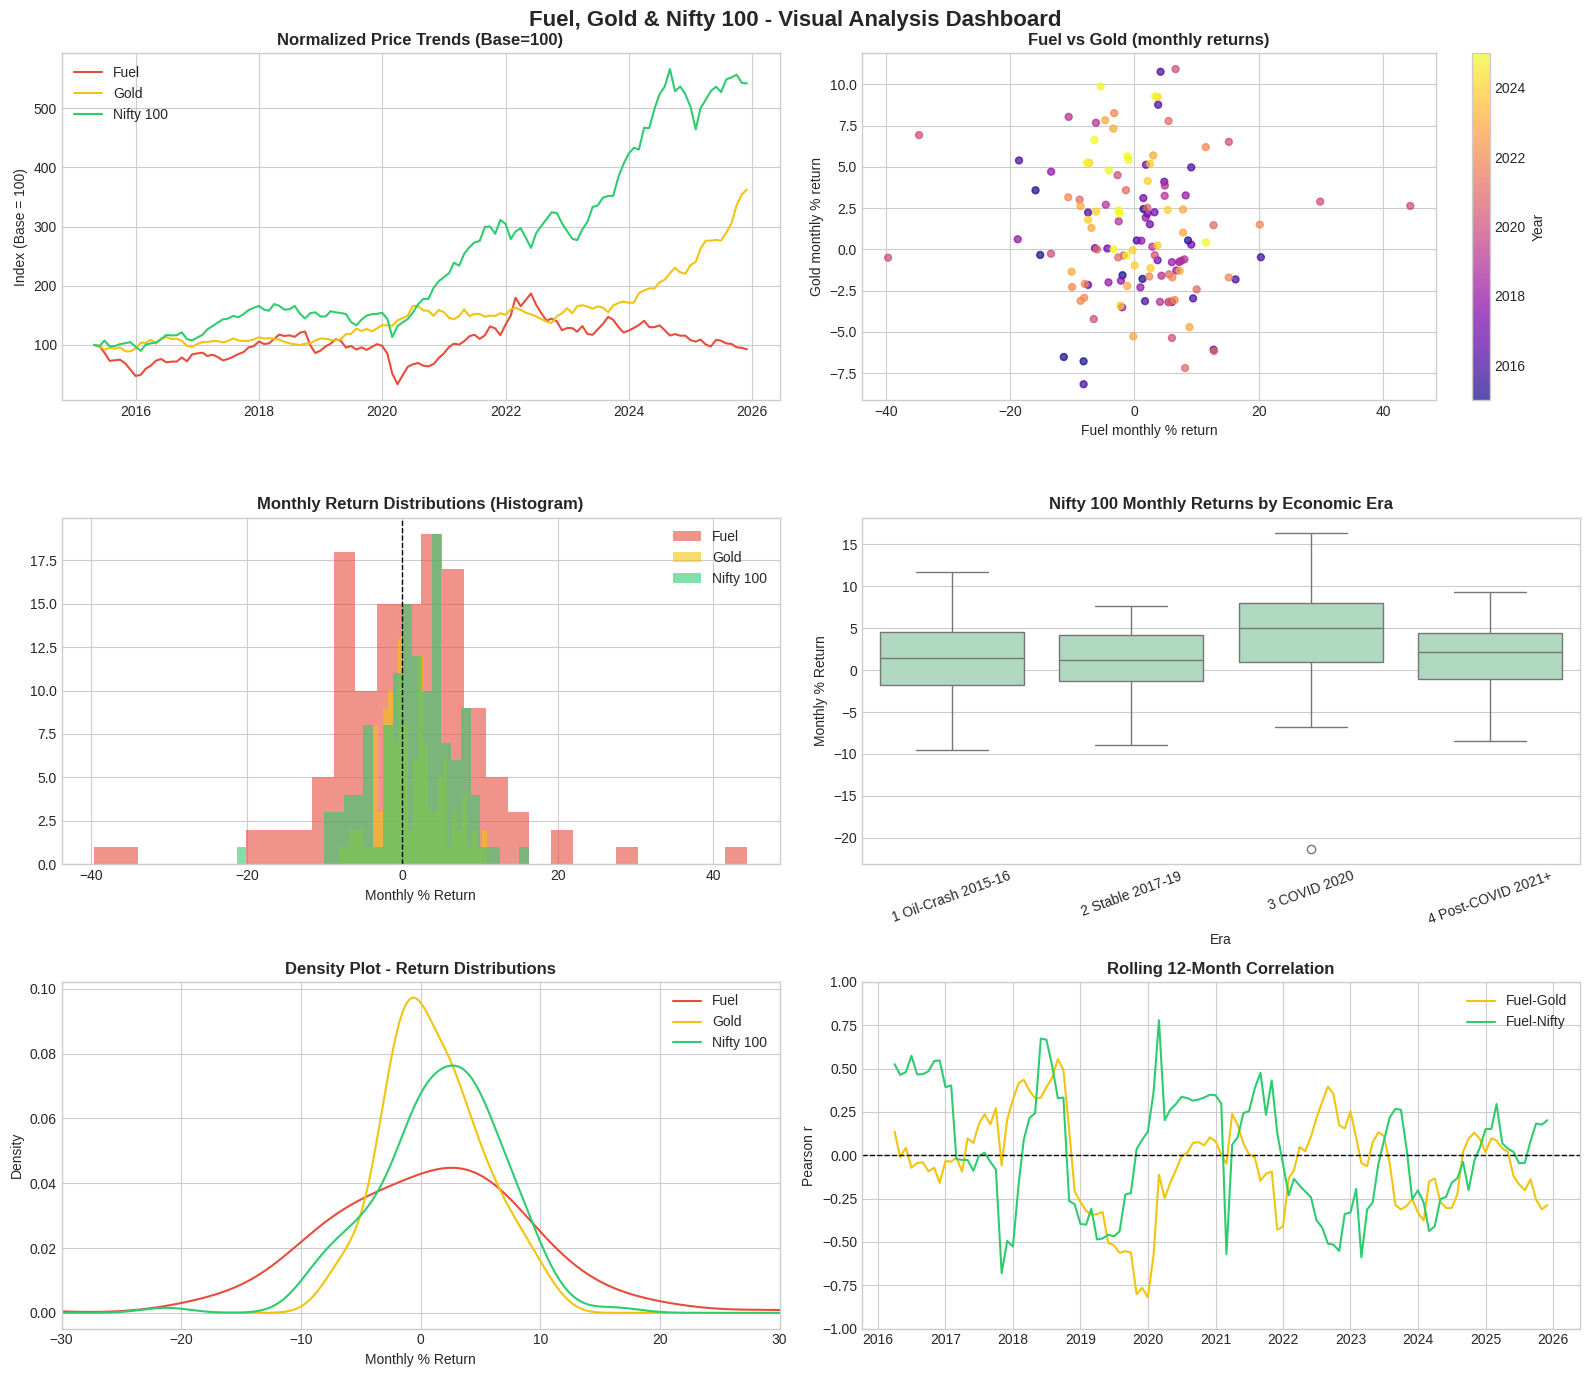


Dashboard saved as visualization_dashboard.png


In [13]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle('Fuel, Gold & Nifty 100 - Visual Analysis Dashboard', fontsize=16, fontweight='bold')

# Plot 1: Line plot - normalized prices
ax1 = axes[0, 0]
base = df.iloc[0]
ax1.plot(df['date'], df['fuel_price']  / base['fuel_price']  * 100, label='Fuel',  color='#E74C3C')
ax1.plot(df['date'], df['gold_price']  / base['gold_price']  * 100, label='Gold',  color='#F1C40F')
ax1.plot(df['date'], df['nifty_close'] / base['nifty_close'] * 100, label='Nifty 100', color='#2ECC71')
ax1.set_title('Normalized Price Trends (Base=100)', fontweight='bold')
ax1.set_ylabel('Index (Base = 100)')
ax1.legend()
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Plot 2: Scatter - Fuel return vs Gold return
ax2 = axes[0, 1]
sc = ax2.scatter(df['fuel_pct'], df['gold_pct'], c=df['year'], cmap='plasma', alpha=0.7, s=25)
plt.colorbar(sc, ax=ax2, label='Year')
ax2.set_xlabel('Fuel monthly % return')
ax2.set_ylabel('Gold monthly % return')
ax2.set_title('Fuel vs Gold (monthly returns)', fontweight='bold')

# Plot 3: Histogram
ax3 = axes[1, 0]
ax3.hist(df['fuel_pct'],  bins=30, alpha=0.6, label='Fuel',  color='#E74C3C')
ax3.hist(df['gold_pct'],  bins=30, alpha=0.6, label='Gold',  color='#F1C40F')
ax3.hist(df['nifty_pct'], bins=30, alpha=0.6, label='Nifty 100', color='#2ECC71')
ax3.axvline(0, color='black', linestyle='--', linewidth=1)
ax3.set_title('Monthly Return Distributions (Histogram)', fontweight='bold')
ax3.set_xlabel('Monthly % Return')
ax3.legend()

# Plot 4: Box plot - Nifty return by era
ax4 = axes[1, 1]
sns.boxplot(data=df, x='era', y='nifty_pct', ax=ax4, color='#A9DFBF', order=sorted(df['era'].unique()))
ax4.set_title('Nifty 100 Monthly Returns by Economic Era', fontweight='bold')
ax4.set_xlabel('Era')
ax4.set_ylabel('Monthly % Return')
ax4.tick_params(axis='x', rotation=20)

# Plot 5: Density plot
ax5 = axes[2, 0]
df['fuel_pct'].plot.density(ax=ax5, label='Fuel',  color='#E74C3C')
df['gold_pct'].plot.density(ax=ax5, label='Gold',  color='#F1C40F')
df['nifty_pct'].plot.density(ax=ax5, label='Nifty 100', color='#2ECC71')
ax5.set_xlim(-30, 30)
ax5.set_title('Density Plot - Return Distributions', fontweight='bold')
ax5.set_xlabel('Monthly % Return')
ax5.legend()

# Plot 6: Rolling correlation
ax6 = axes[2, 1]
ax6.plot(df['date'], df['fuel_pct'].rolling(12).corr(df['gold_pct']),  label='Fuel-Gold',  color='#F1C40F')
ax6.plot(df['date'], df['fuel_pct'].rolling(12).corr(df['nifty_pct']), label='Fuel-Nifty', color='#2ECC71')
ax6.axhline(0, color='black', linestyle='--', linewidth=1)
ax6.set_ylim(-1, 1)
ax6.set_title('Rolling 12-Month Correlation', fontweight='bold')
ax6.set_ylabel('Pearson r')
ax6.legend()

plt.tight_layout()
plt.savefig('visualization_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nDashboard saved as visualization_dashboard.png")

In [14]:
!pip install mlxtend --quiet
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Each month becomes one "basket" of events
def make_transactions(row):
    items = []
    if row['fuel_pct'] > 2:    items.append('Fuel_Rises')
    if row['fuel_pct'] < -2:   items.append('Fuel_Falls')
    if row['gold_pct'] > 2:    items.append('Gold_Rises')
    if row['gold_pct'] < -2:   items.append('Gold_Falls')
    if row['nifty_next_dir'] == 1:
        items.append('Next_Nifty_Up')
    else:
        items.append('Next_Nifty_Down')
    return items

transactions = df.apply(make_transactions, axis=1).tolist()

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

frequent_items = apriori(basket, min_support=0.1, use_colnames=True)
try:
    rules = association_rules(frequent_items, metric='confidence', min_threshold=0.5)
except TypeError:      # newer mlxtend versions need num_itemsets
    rules = association_rules(frequent_items, num_itemsets=len(basket), metric='confidence', min_threshold=0.5)
rules = rules.sort_values('lift', ascending=False)

print(f"Total rules found: {len(rules)}")

# keep only rules that predict next-month Nifty
nifty_rules = rules[rules['consequents'].apply(lambda x: any('Next_Nifty' in i for i in x))]
nifty_rules = nifty_rules[nifty_rules['antecedents'].apply(lambda x: not any('Next_Nifty' in i for i in x))]
print(f"\n--- Rules that predict next-month Nifty ({len(nifty_rules)} found) ---")
display(nifty_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).round(3))
print("Lift close to 1 means the rule is no better than chance.")

Total rules found: 7

--- Rules that predict next-month Nifty (5 found) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
6,"(Gold_Rises, Fuel_Rises)",(Next_Nifty_Up),0.148,0.826,1.259
3,(Gold_Falls),(Next_Nifty_Up),0.148,0.704,1.072
2,(Fuel_Rises),(Next_Nifty_Up),0.320,0.683,1.041
4,(Gold_Rises),(Next_Nifty_Up),0.273,0.673,1.026
1,(Fuel_Falls),(Next_Nifty_Up),0.203,0.542,0.825


Lift close to 1 means the rule is no better than chance.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Train months: 102 | Test months: 26

--- Model 1: Linear Regression (Predict next-month Gold return %) ---
R2 Score : -0.6007   (baseline = -0.5534)
MAE      : 3.900   (baseline = 3.669)
RMSE     : 4.917
R2 close to 0 or negative = model is not better than guessing the average.

Coefficients:
  fuel_pct       : -0.0081
  fuel_pct_lag1  : -0.0160
  fuel_pct_lag2  : -0.0564
  gold_pct       : -0.0832
  nifty_pct      : -0.0849

--- Model 2: Logistic Regression (Predict Nifty Up/Down next month) ---
Accuracy: 0.6154   (always guessing the commoner direction = 0.6154)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

  Nifty Down       0.00      0.00      0.00        10
    Nifty Up       0.62      1.00      0.76        16

    accuracy                           0.62        26
   macro avg       0.31      0.50      0.38        26
weighted avg       0.38      0.62      0.47        26



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

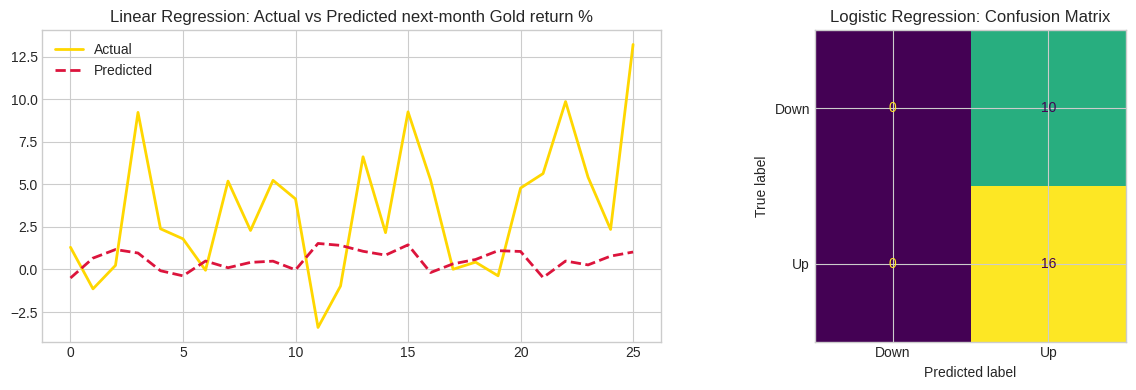

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [15]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.preprocessing import StandardScaler

# Features known at the end of THIS month
features = ['fuel_pct', 'fuel_pct_lag1', 'fuel_pct_lag2', 'gold_pct', 'nifty_pct']
split = int(len(df) * 0.8)                       # first 80% train, last 20% test
X_train, X_test = df[features][:split], df[features][split:]
print("Train months:", len(X_train), "| Test months:", len(X_test))

# ---------- Model 1: Linear Regression -> next month GOLD return ----------
print("\n--- Model 1: Linear Regression (Predict next-month Gold return %) ---")
y_train, y_test = df['gold_next_pct'][:split], df['gold_next_pct'][split:]

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

baseline = np.full(len(y_test), y_train.mean())          # naive guess = average of training data
print(f"R2 Score : {r2_score(y_test, y_pred_lr):.4f}   (baseline = {r2_score(y_test, baseline):.4f})")
print(f"MAE      : {mean_absolute_error(y_test, y_pred_lr):.3f}   (baseline = {mean_absolute_error(y_test, baseline):.3f})")
print(f"RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.3f}")
print("R2 close to 0 or negative = model is not better than guessing the average.")
print("\nCoefficients:")
for feat, coef in zip(features, lr_model.coef_):
    print(f"  {feat:15s}: {coef:.4f}")

# ---------- Model 2: Logistic Regression -> next month NIFTY direction ----------
print("\n--- Model 2: Logistic Regression (Predict Nifty Up/Down next month) ---")
yc_train, yc_test = df['nifty_next_dir'][:split], df['nifty_next_dir'][split:]

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_sc, yc_train)
y_pred_lg = log_model.predict(X_test_sc)

majority = max(yc_test.mean(), 1 - yc_test.mean())
print(f"Accuracy: {accuracy_score(yc_test, y_pred_lg):.4f}   (always guessing the commoner direction = {majority:.4f})")
print(classification_report(yc_test, y_pred_lg, target_names=['Nifty Down', 'Nifty Up'], zero_division=0))

# Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(y_test.values, label='Actual',    color='gold',    linewidth=2)
axes[0].plot(y_pred_lr,     label='Predicted', color='crimson', linewidth=2, linestyle='--')
axes[0].set_title('Linear Regression: Actual vs Predicted next-month Gold return %')
axes[0].legend()
cm = confusion_matrix(yc_test, y_pred_lg, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['Down', 'Up']).plot(ax=axes[1], colorbar=False)
axes[1].set_title('Logistic Regression: Confusion Matrix')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

--- Naive Bayes Classifier ---
Accuracy: 0.5769
              precision    recall  f1-score   support

        Down       0.46      0.60      0.52        10
          Up       0.69      0.56      0.62        16

    accuracy                           0.58        26
   macro avg       0.58      0.58      0.57        26
weighted avg       0.60      0.58      0.58        26

--- Decision Tree Classifier ---
Accuracy: 0.6154
              precision    recall  f1-score   support

        Down       0.50      0.10      0.17        10
          Up       0.62      0.94      0.75        16

    accuracy                           0.62        26
   macro avg       0.56      0.52      0.46        26
weighted avg       0.58      0.62      0.53        26



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

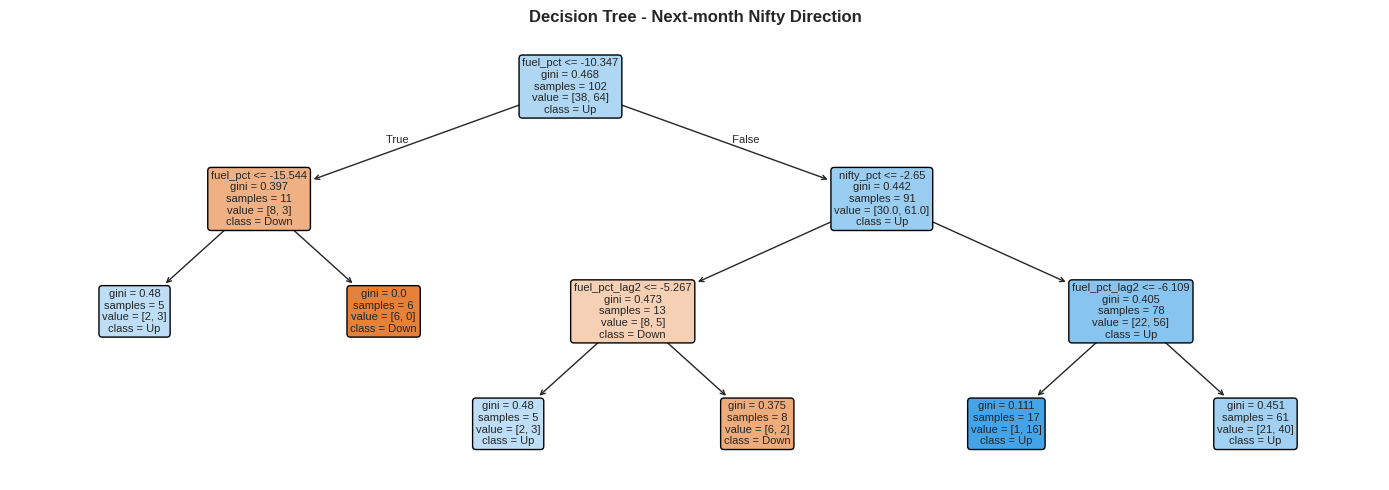

--- Model Comparison Summary ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Accuracy
0,Guess commoner direction (baseline),0.6154
1,Logistic Regression,0.6154
2,Naive Bayes,0.5769
3,Decision Tree,0.6154


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [21]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Model 1: Naive Bayes
print("--- Naive Bayes Classifier ---")
nb = GaussianNB()
nb.fit(X_train, yc_train)
nb_pred = nb.predict(X_test)
print(f"Accuracy: {accuracy_score(yc_test, nb_pred):.4f}")
print(classification_report(yc_test, nb_pred, target_names=['Down', 'Up'], zero_division=0))

# Model 2: Decision Tree (small depth so it does not memorise)
print("--- Decision Tree Classifier ---")
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)
dt.fit(X_train, yc_train)
dt_pred = dt.predict(X_test)
print(f"Accuracy: {accuracy_score(yc_test, dt_pred):.4f}")
print(classification_report(yc_test, dt_pred, target_names=['Down', 'Up'], zero_division=0))

# Visualize Decision Tree
plt.figure(figsize=(14, 5))
plot_tree(dt, feature_names=features, class_names=['Down', 'Up'], filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree - Next-month Nifty Direction', fontweight='bold')
plt.tight_layout()
plt.show()

# Model comparison table
print("--- Model Comparison Summary ---")
models_summary = pd.DataFrame({
    'Model': ['Guess commoner direction (baseline)', 'Logistic Regression', 'Naive Bayes', 'Decision Tree'],
    'Accuracy': [round(majority, 4),
                 round(accuracy_score(yc_test, y_pred_lg), 4),
                 round(accuracy_score(yc_test, nb_pred), 4),
                 round(accuracy_score(yc_test, dt_pred), 4)]
})
display(models_summary)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Silhouette score for each k: {2: np.float64(0.252), 3: np.float64(0.237), 4: np.float64(0.251), 5: np.float64(0.255), 6: np.float64(0.245), 7: np.float64(0.244)}
Selected k = 5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

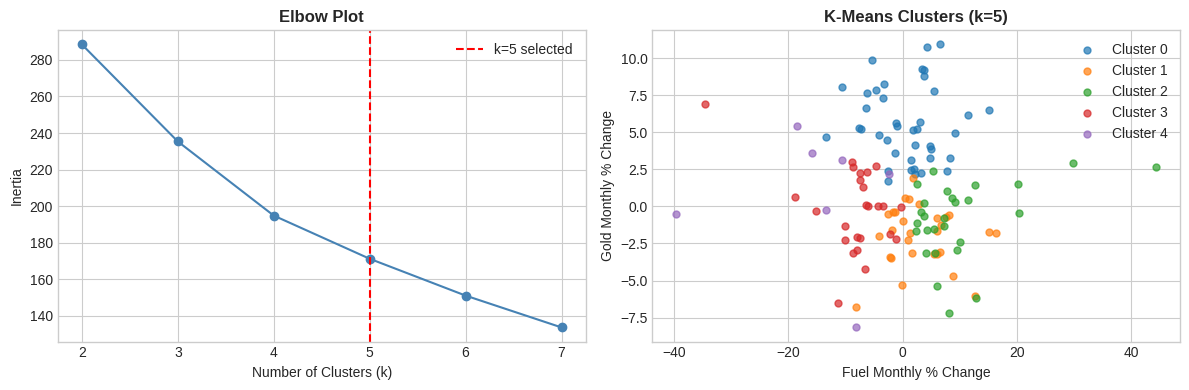

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

--- Cluster Profiles (average monthly % change) ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,fuel_pct,gold_pct,nifty_pct,months
cluster,,,,
0,0.74,5.57,0.86,40
1,3.14,-1.98,-2.01,29
2,9.95,-0.92,5.47,27
3,-8.51,-0.22,5.52,25
4,-15.55,0.77,-9.53,7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


--- Era vs Cluster composition ---


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

cluster,0,1,2,3,4
era,,,,,
1 Oil-Crash 2015-16,4,7,3,3,3
2 Stable 2017-19,12,12,6,6,0
3 COVID 2020,3,1,4,2,2
4 Post-COVID 2021+,21,9,14,14,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features_kmeans = ['fuel_pct', 'gold_pct', 'nifty_pct']
X_km_sc = StandardScaler().fit_transform(df[features_kmeans])

# Elbow plot + silhouette score
inertias = []
K_range = range(2, 8)
sil_scores = {}
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_km_sc)
    inertias.append(km.inertia_)
    sil_scores[k] = silhouette_score(X_km_sc, km.labels_)
print("Silhouette score for each k:", {k: round(v, 3) for k, v in sil_scores.items()})

best_k = max([3, 4, 5], key=lambda k: sil_scores[k])      # choose best k between 3 and 5
print("Selected k =", best_k)

km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df_km = df[features_kmeans + ['date', 'era']].copy()
df_km['cluster'] = km_final.fit_predict(X_km_sc)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(K_range, inertias, 'o-', color='steelblue')
plt.axvline(x=best_k, color='red', linestyle='--', label=f'k={best_k} selected')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Plot', fontweight='bold')
plt.legend()

plt.subplot(1, 2, 2)
for c in range(best_k):
    sub = df_km[df_km['cluster'] == c]
    plt.scatter(sub['fuel_pct'], sub['gold_pct'], label=f'Cluster {c}', alpha=0.7, s=25)
plt.xlabel('Fuel Monthly % Change')
plt.ylabel('Gold Monthly % Change')
plt.title(f'K-Means Clusters (k={best_k})', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print("--- Cluster Profiles (average monthly % change) ---")
profile = df_km.groupby('cluster')[features_kmeans].mean().round(2)
profile['months'] = df_km.groupby('cluster').size()
display(profile)

print("--- Era vs Cluster composition ---")
display(pd.crosstab(df_km['era'], df_km['cluster']))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

--- ADF Test on PRICES ---
fuel_price  : ADF = -1.9495, p = 0.3091 -> Non-Stationary
gold_price  : ADF = 4.9828, p = 1.0000 -> Non-Stationary
nifty_close : ADF = 0.9193, p = 0.9933 -> Non-Stationary

--- ADF Test on monthly RETURNS (after removing the trend) ---
fuel_pct    : ADF = -8.8336, p = 0.0000 -> Stationary
gold_pct    : ADF = -10.7807, p = 0.0000 -> Stationary
nifty_pct   : ADF = -3.5322, p = 0.0072 -> Stationary


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

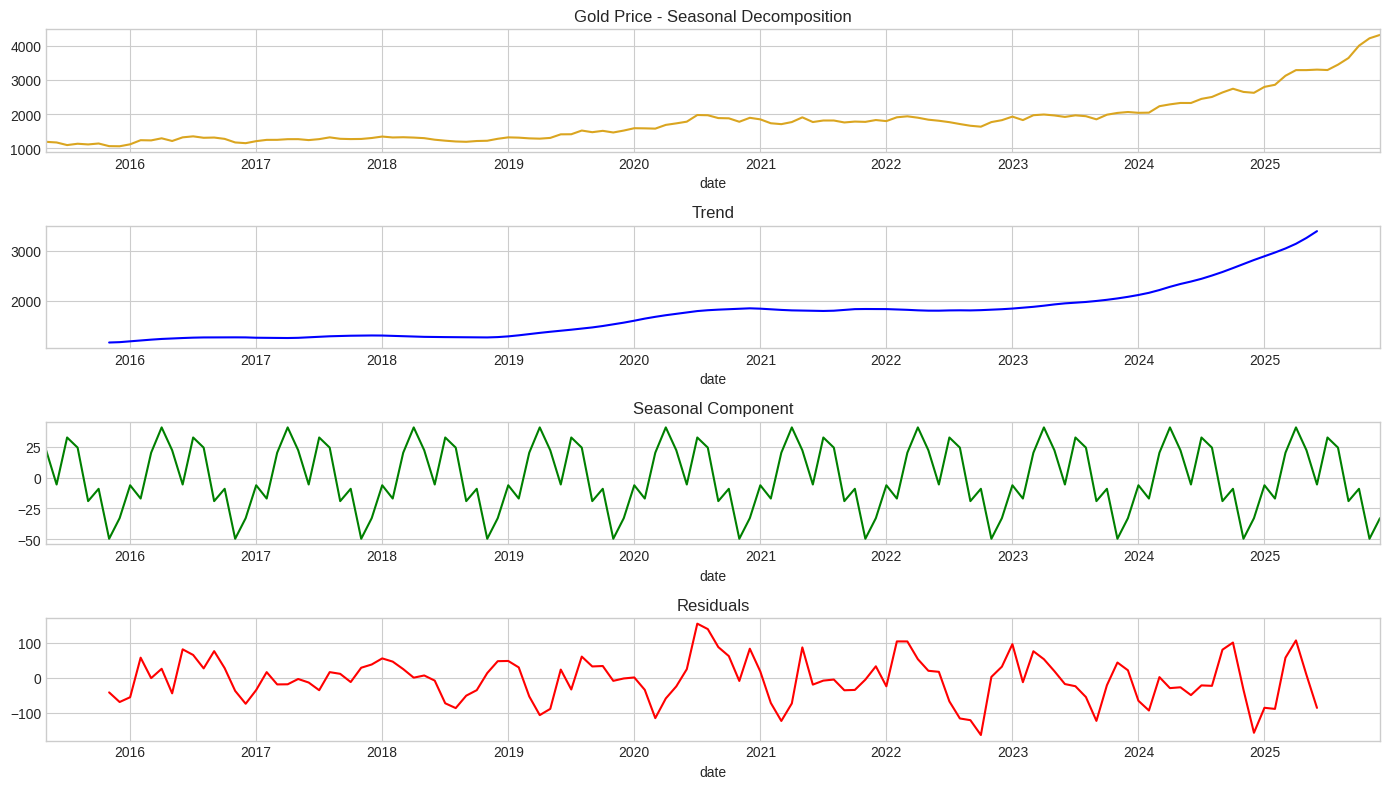

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


--- Does fuel_pct help predict gold_pct? ---
  Lag 1: p = 0.6356 -> Not significant
  Lag 2: p = 0.5322 -> Not significant
  Lag 3: p = 0.3541 -> Not significant

--- Does fuel_pct help predict nifty_pct? ---
  Lag 1: p = 0.4748 -> Not significant
  Lag 2: p = 0.2496 -> Not significant
  Lag 3: p = 0.5079 -> Not significant


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [18]:
import io, contextlib
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.seasonal import seasonal_decompose

# ADF Stationarity Test (p < 0.05 -> stationary)
print("--- ADF Test on PRICES ---")
for col in ['fuel_price', 'gold_price', 'nifty_close']:
    result = adfuller(df[col])
    status = 'Stationary' if result[1] < 0.05 else 'Non-Stationary'
    print(f"{col:12s}: ADF = {result[0]:.4f}, p = {result[1]:.4f} -> {status}")

print("\n--- ADF Test on monthly RETURNS (after removing the trend) ---")
for col in ['fuel_pct', 'gold_pct', 'nifty_pct']:
    result = adfuller(df[col])
    status = 'Stationary' if result[1] < 0.05 else 'Non-Stationary'
    print(f"{col:12s}: ADF = {result[0]:.4f}, p = {result[1]:.4f} -> {status}")

# Seasonal decomposition of gold price
gold_series = df.set_index('date')['gold_price']
decomp = seasonal_decompose(gold_series, model='additive', period=12)
fig, axes = plt.subplots(4, 1, figsize=(14, 8))
decomp.observed.plot(ax=axes[0], title='Gold Price - Seasonal Decomposition', color='goldenrod')
decomp.trend.plot(ax=axes[1], title='Trend', color='blue')
decomp.seasonal.plot(ax=axes[2], title='Seasonal Component', color='green')
decomp.resid.plot(ax=axes[3], title='Residuals', color='red')
plt.tight_layout()
plt.show()

# Granger causality on RETURNS: does fuel help predict gold / nifty?
def granger(effect, cause, maxlag=3):
    data = df[[effect, cause]]
    with contextlib.redirect_stdout(io.StringIO()):          # hide the long default printout
        res = grangercausalitytests(data, maxlag=maxlag)
    print(f"\n--- Does {cause} help predict {effect}? ---")
    for lag in range(1, maxlag + 1):
        p = res[lag][0]['ssr_ftest'][1]
        print(f"  Lag {lag}: p = {p:.4f} -> {'Significant' if p < 0.05 else 'Not significant'}")

granger('gold_pct',  'fuel_pct')
granger('nifty_pct', 'fuel_pct')

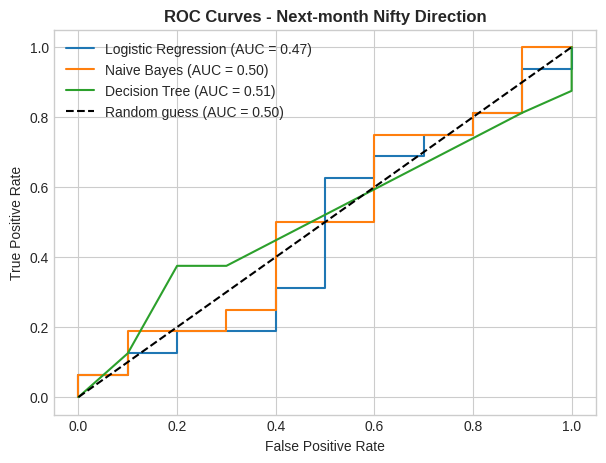

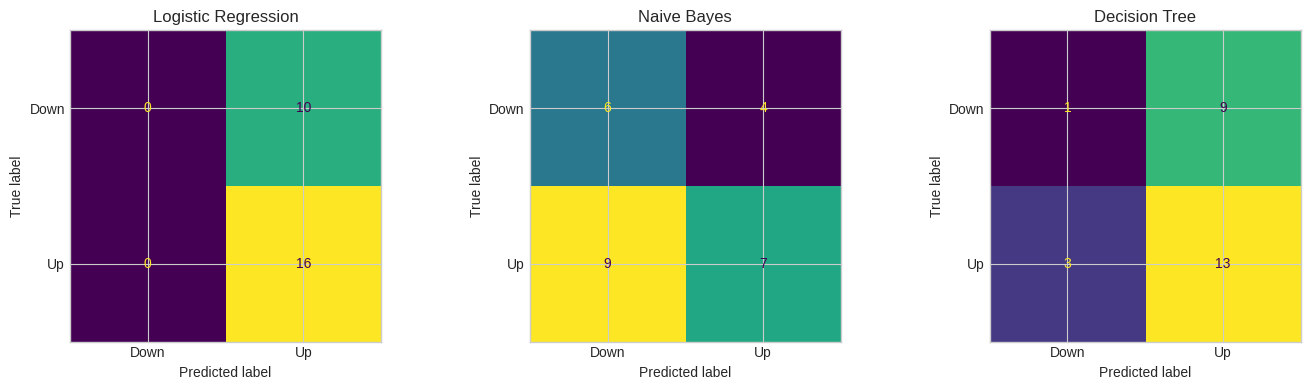

--- Final comparison: Test AUC and Cross-Validated AUC ---


,Model,Test AUC,CV AUC
0,Logistic Regression,0.469,0.477
1,Naive Bayes,0.500,0.440
2,Decision Tree,0.509,0.414


AUC = 0.50 means a coin flip. 0.55-0.60 = weak signal. Above 0.65 = useful signal.


In [22]:
import warnings
# Suppress both Python level warnings and Jupyter/IPython internal display warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore')

import logging
logging.captureWarnings(True)

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np

# Fallback definition setup
if 'log_model' not in globals():
    log_model = LogisticRegression(max_iter=1000)
    log_model.fit(X_train_sc, yc_train)
    y_pred_lg = log_model.predict(X_test_sc)

if 'nb' not in globals():
    nb = GaussianNB()
    nb.fit(X_train, yc_train)
    nb_pred = nb.predict(X_test)

if 'dt' not in globals():
    dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)
    dt.fit(X_train, yc_train)
    dt_pred = dt.predict(X_test)

# Probability predictions on the test set
prob_lg = log_model.predict_proba(X_test_sc)[:, 1]
prob_nb = nb.predict_proba(X_test)[:, 1]
prob_dt = dt.predict_proba(X_test)[:, 1]

# ROC curves
plt.figure(figsize=(7, 5))
for name, prob in [('Logistic Regression', prob_lg), ('Naive Bayes', prob_nb), ('Decision Tree', prob_dt)]:
    fpr, tpr, _ = roc_curve(yc_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yc_test, prob):.2f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Next-month Nifty Direction', fontweight='bold')
plt.legend()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pred) in zip(axes, [('Logistic Regression', y_pred_lg), ('Naive Bayes', nb_pred), ('Decision Tree', dt_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(yc_test, pred, labels=[0, 1]), display_labels=['Down', 'Up']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Time-series cross-validation
X_all, y_all = df[features], df['nifty_next_dir']
cv = TimeSeriesSplit(n_splits=5)
cv_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=42)
}

print("--- Final comparison: Test AUC and Cross-Validated AUC ---")
rows = []
for (name, prob), (_, model) in zip([('Logistic Regression', prob_lg), ('Naive Bayes', prob_nb), ('Decision Tree', prob_dt)], cv_models.items()):
    cv_auc = cross_val_score(model, X_all, y_all, cv=cv, scoring='roc_auc').mean()
    rows.append({'Model': name, 'Test AUC': round(roc_auc_score(yc_test, prob), 3), 'CV AUC': round(cv_auc, 3)})
display(pd.DataFrame(rows))
print("AUC = 0.50 means a coin flip. 0.55-0.60 = weak signal. Above 0.65 = useful signal.")